# **Phase 2 - Transfer Learning & Data Augmentations**

**Students:** Samarth Kale, Saarth Kishore

Please follow the notebook in order. Make sure to add code where indicated by `''' TODO '''` or `# YOUR CODE HERE`. Please answer all questions indicated with '❓', and answer where it says 'ANSWER HERE'.

Ensure your notebook is easy to follow. All written report answers should be provided in the notebook itself.


In [3]:
import torch
import torch.nn as nn
import torchvision.models as models
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import time
import os
import copy

import matplotlib.pyplot as plt
import numpy as np
import torchvision

## **Overview**
1. CIFAR10 Dataset
2. Data Augmentations
3. Transfer learning with ResNet Architecture
4. Training ResNet Architecture

# **1. CIFAR10 Dataset**

This is an RGB dataset with 10 classes:

*plane, car, bird, cat, deer, dog, frog, horse, ship, truck*


## **1.1 Download and Load CIFAR10**

You can find CIFAR10 in ```torchvision.datasets.CIFAR10()``` or see [here](https://pytorch.org/vision/0.15/generated/torchvision.datasets.CIFAR10.html#torchvision.datasets.CIFAR10). Please Download the dataset and use Dataloaders to load it. This is identical to loading MNIST.

In [4]:
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 128
NUM_WORKERS = 0   # keep 0 when running Jupyter on Windows; 2-4 is fine on Colab/Linux
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)

# Load CIFAR-10 training set
train_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

# Load CIFAR-10 test set
testset = datasets.CIFAR10(root='./data', train=False, download=True, transform=transform)

test_loader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS)

classes = ('plane', 'car', 'bird', 'cat',
           'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Using device: cuda:0


100.0%


## **1.2 Display CIFAR10 Images**

Similar to Phase 1, please complete `show_imgs()` function to display 10 images. However, this time we want to display exactly one image per class. There are 10 classes total. Show a random image per class with their label.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

def show_imgs(dataloader, classes):
    """Shows one random image per class (applies whatever transform the loader's dataset has)."""
    dataset = dataloader.dataset
    targets = np.array(dataset.targets)
    fig, axes = plt.subplots(1, len(classes), figsize=(2 * len(classes), 2.6))
    for c, ax in enumerate(axes):
        idx = np.random.choice(np.where(targets == c)[0])
        img, label = dataset[idx]
        img = img * 0.5 + 0.5                       # undo Normalize((0.5,)*3, (0.5,)*3)
        img = img.clamp(0, 1).permute(1, 2, 0).numpy()
        ax.imshow(img)
        ax.set_title(classes[label])
        ax.axis('off')
    plt.tight_layout()
    plt.show()

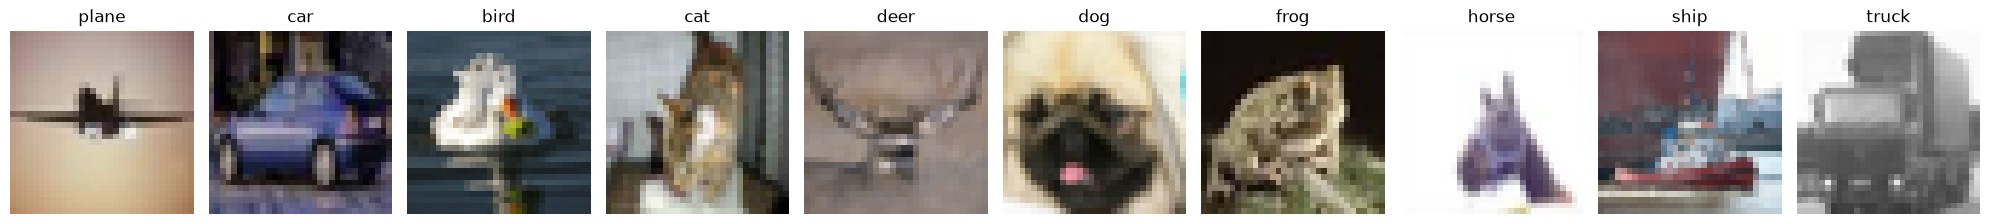

In [6]:
show_imgs(train_loader, classes)

# **2. Data Augmentations**

## **2.1 Use Built-in Augmentations**

Use augmentations from the `torchvision.transforms` library [
link](https://pytorch.org/vision/0.9/transforms.html). Apply the following. For the parameters, please test and choose suitable ones.


*   Horizontal Flip
*   Random Crop
*   Color Jitter
*   Random Resized Crop

Try each of these individually and display the augmented images using your `show_imgs()` function.

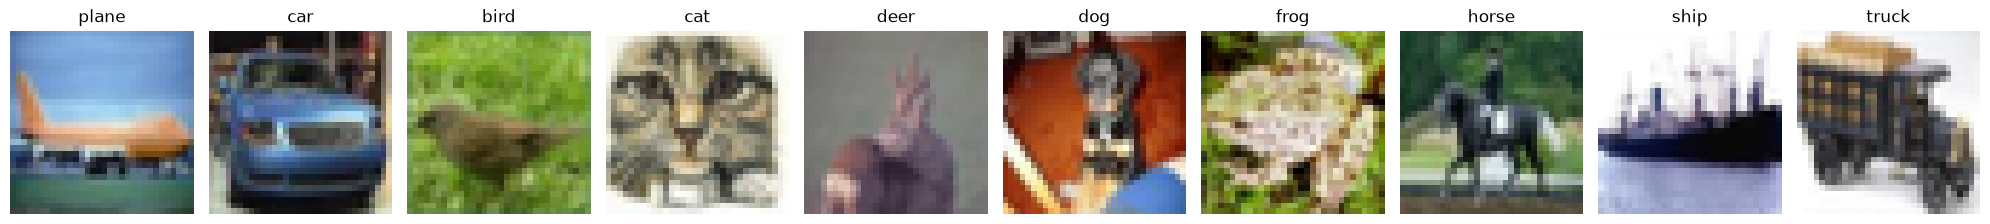

In [7]:
# Horizontal Flip (p=1.0 so the effect is visible here; p=0.5 is used for training)
aug_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=1.0),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Define a dataset & loader with augmentations
train_aug_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=aug_transform)
train_aug_loader = torch.utils.data.DataLoader(train_aug_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

# Display images with augmentations
show_imgs(train_aug_loader, classes)

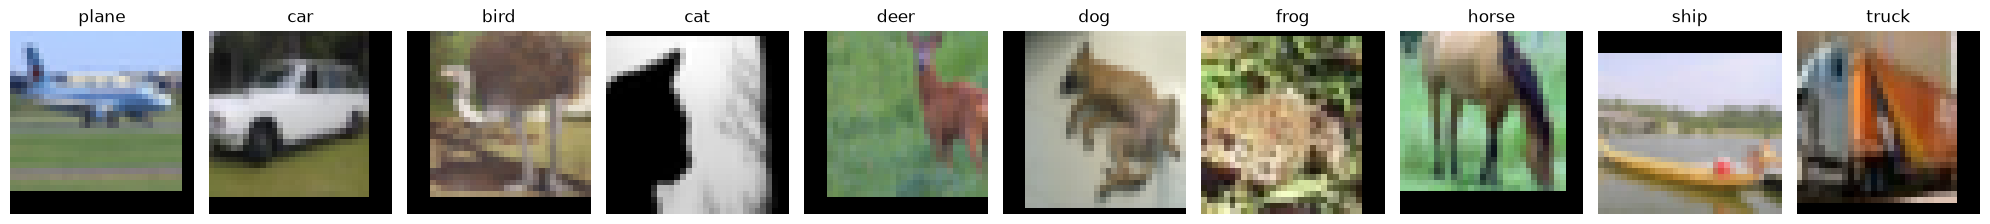

In [8]:
# Random Crop: pad 4 px then crop back to 32x32 -> small random translations
aug_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Define a dataset & loader with augmentations
train_aug_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=aug_transform)
train_aug_loader = torch.utils.data.DataLoader(train_aug_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

# Display images with augmentations
show_imgs(train_aug_loader, classes)

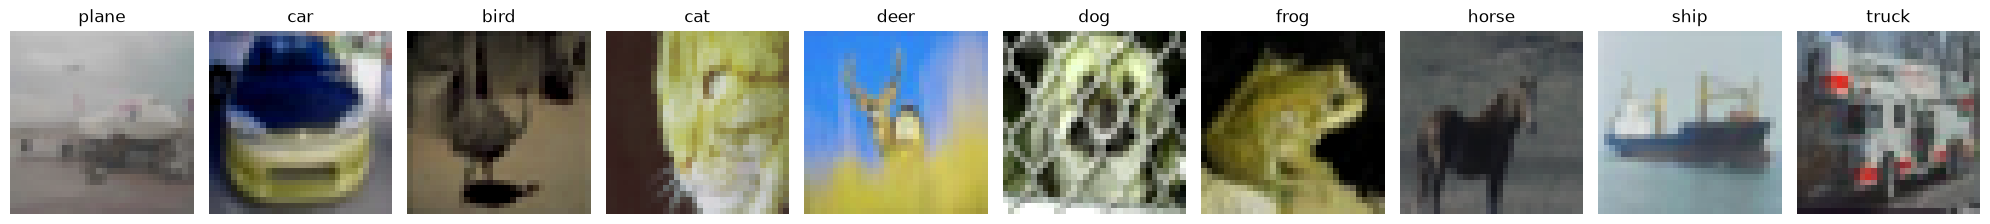

In [9]:
# Color Jitter
aug_transform = transforms.Compose([
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.4, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Define a dataset & loader with augmentations
train_aug_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=aug_transform)
train_aug_loader = torch.utils.data.DataLoader(train_aug_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

# Display images with augmentations
show_imgs(train_aug_loader, classes)

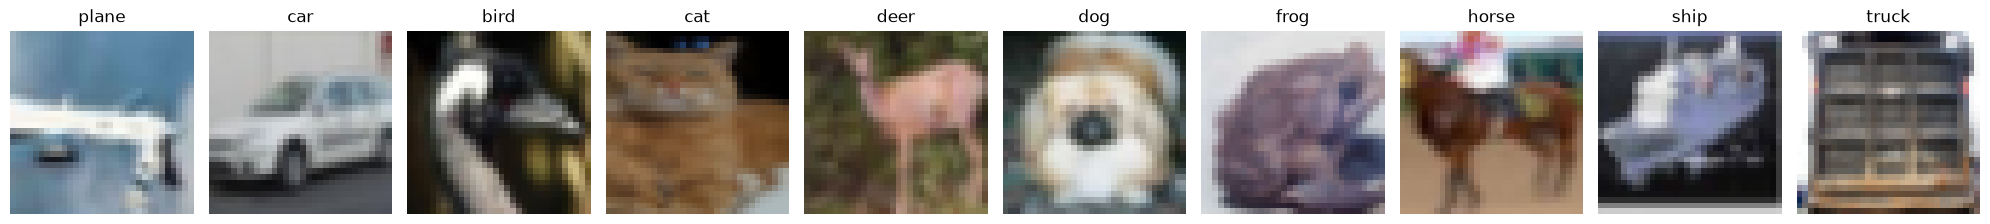

In [10]:
# Random Resized Crop: crop 60-100% of the image, resize back to 32x32
aug_transform = transforms.Compose([
    transforms.RandomResizedCrop(32, scale=(0.6, 1.0), ratio=(0.8, 1.25)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Define a dataset & loader with augmentations
train_aug_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=aug_transform)
train_aug_loader = torch.utils.data.DataLoader(train_aug_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

# Display images with augmentations
show_imgs(train_aug_loader, classes)

### ❓ **Q 2.1.1 Please explain what Data augmentations are and their use. What is the purpose of making them random?**

Data augmentations are transformations applied to training images (flips, crops, color changes) to create new variations of the data without collecting more. They help the model generalize and reduce overfitting. They are random so the model sees a different version of each image every epoch, which keeps it from memorizing exact pixels and teaches it that the label does not depend on those changes.

___
### ❓ **Q 2.1.2 Please explain all of the augmentations you are using. What is the value of each of them?**

- **Horizontal Flip:** mirrors the image. A car or cat facing left is still the same class, so this teaches orientation invariance.
- **Random Crop (padding 4):** shifts the object slightly within the frame, which teaches position invariance.
- **Color Jitter:** randomly changes brightness, contrast, saturation and hue, which builds robustness to lighting and camera differences.
- **Random Resized Crop:** crops 60–100% of the image and resizes it back, which teaches scale invariance and recognizing partially visible objects.

## **2.2 Custom Augmentations**

Create a custom data augmentation function. Please do rotation, randomly between -30 and 30 degrees. You must code this yourself, do not use the torchvision function.

[This tutorial ](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html) may be useful. You can use `PIL` image manupilation libraries, but NOT torchvision ones. Do not import any other libraries. You should only need:



```
from PIL import Image
import random
```





Apply this custom augmentation to the images and display the results using `show_imgs()`.

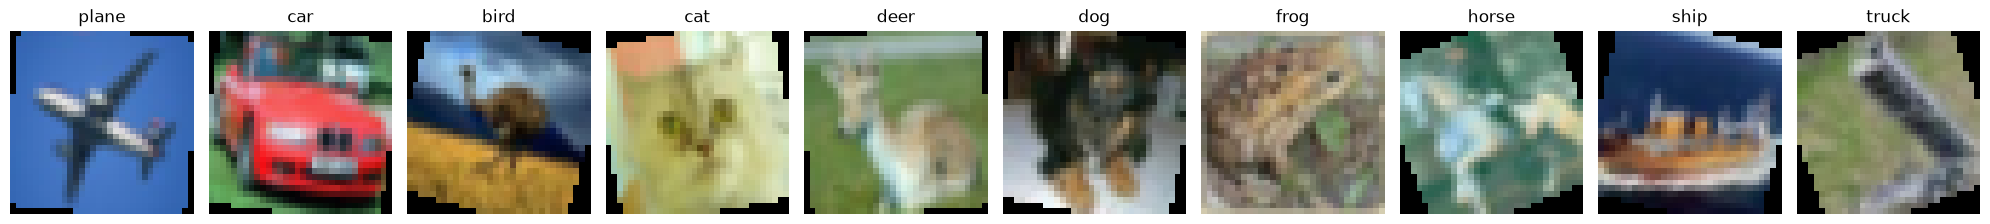

In [11]:
from PIL import Image
import random

class RandomRotate:
    """Rotates a PIL image by a random angle in [min_angle, max_angle] degrees."""
    def __init__(self, min_angle=-30, max_angle=30):
        self.min_angle = min_angle
        self.max_angle = max_angle

    def __call__(self, img):
        angle = random.uniform(self.min_angle, self.max_angle)
        # BILINEAR for smooth edges; corners outside the original image are filled with black
        return img.rotate(angle, resample=Image.BILINEAR)

    def __repr__(self):
        return f'RandomRotate({self.min_angle}, {self.max_angle})'

# Apply Transform (must come before ToTensor since it works on PIL images)
rotate_transform = transforms.Compose([
    RandomRotate(-30, 30),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_rotate_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=rotate_transform)
train_loader_rotate = torch.utils.data.DataLoader(train_rotate_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

# Display images with the custom augmentation
show_imgs(train_loader_rotate, classes)

### ❓ **Q 2.2.1 Explain how you would determine what is a good lower and upper limit for rotation? We use -30 to 30, why does that make sense?**

Pick limits that produce images the model could realistically see without changing the label, and check visually that the rotated images still look natural. ±30° covers realistic tilts (camera angle, a tilted object). Larger angles create unnatural images (an upside-down truck) and large black corners, which add noise instead of useful variety. For tasks where orientation matters (e.g. telling 6 from 9), the range should be even smaller.

____

# **3. Transfer Learning**
Load ResNet18 model from ```torchvision.models.resnet18()```, make sure to load pretrained model with [weights](https://pytorch.org/vision/stable/models.html).
You will need to modify the final layer. ResNet outputs 100 labels - please change to the correct output dimension.

## **3.1 ResNet18**

In [12]:
from torchvision.models import resnet18, ResNet18_Weights

# Helper to build a fresh pretrained model (each experiment below starts from ImageNet weights).
# Note: we call models.resnet18 rather than resnet18(...) because the cell below reassigns
# the name `resnet18` to a model, which would break later calls.
def make_resnet18(num_classes=10):
    model = models.resnet18(weights=ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, num_classes)   # 512 -> 10
    return model

# Instantiate Pretrained ResNet18
resnet18 = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Modify final layer (ImageNet head has 1000 outputs; CIFAR10 has 10)
resnet18.fc = nn.Linear(resnet18.fc.in_features, len(classes))

# Load onto GPU
resnet18 = resnet18.to(device)

# View Model to validate
print(resnet18)

2.0%

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\Samarth/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## **3.2 Train ResNet on CIFAR10**

### **3.2.1 Train and Test Functions**
You can refer to Phase_1.ipynb to complete these functions. In ```train()```, rather than saving the accuracy and loss per iteration, you will need to save the loss and accuracy ***per epoch***. Plot loss and accuracy plots for both train and validation sets.

In [13]:
# Train Function
def train(model, loss_fn, optimizer, train_loader, val_loader, num_epochs, device, scheduler=None):
    """Trains and records loss/accuracy per epoch for train and validation sets.
    Restores the weights from the epoch with the best validation accuracy at the end."""
    model.to(device)
    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_acc, best_wts = 0.0, copy.deepcopy(model.state_dict())

    for epoch in range(num_epochs):
        start = time.time()
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        if scheduler is not None:
            scheduler.step()

        train_loss, train_acc = running_loss / total, 100 * correct / total
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        if val_acc > best_acc:
            best_acc, best_wts = val_acc, copy.deepcopy(model.state_dict())

        print(f'Epoch [{epoch + 1}/{num_epochs}]  '
              f'Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.2f}%  |  '
              f'Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.2f}%  |  {time.time() - start:.1f}s')

    model.load_state_dict(best_wts)
    print(f'Best val accuracy: {best_acc:.2f}%')
    return history


def evaluate(model, loader, loss_fn, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            running_loss += loss_fn(outputs, labels).item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return running_loss / total, 100 * correct / total


# Test Function
def test_accuracy(model, test_loader, device):
    model.to(device)
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            preds = model(images).argmax(1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
    acc = 100 * correct / total
    print(f'Test Accuracy: {acc:.2f}%')
    return acc


# Plot Learning Curves
def plot_learning_curve(history, title=''):
    epochs = range(1, len(history['train_loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
    axes[0].plot(epochs, history['train_loss'], 'o-', label='Train')
    axes[0].plot(epochs, history['val_loss'], 'o-', label='Validation')
    axes[0].set_title(f'Loss {title}'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()
    axes[1].plot(epochs, history['train_acc'], 'o-', label='Train')
    axes[1].plot(epochs, history['val_acc'], 'o-', label='Validation')
    axes[1].set_title(f'Accuracy {title}'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy (%)'); axes[1].legend()
    plt.tight_layout()
    plt.show()


# Shared training setup so every experiment is directly comparable
LR = 0.01
MOMENTUM = 0.9
WEIGHT_DECAY = 5e-4

def make_optimizer_and_scheduler(model, num_epochs):
    params = [p for p in model.parameters() if p.requires_grad]   # only trainable params (matters when frozen)
    optimizer = torch.optim.SGD(params, lr=LR, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)
    return optimizer, scheduler

# Augmented training loader used for the "with augmentations" runs
train_aug_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
train_aug_set = datasets.CIFAR10(root='./data', train=True, download=True, transform=train_aug_transform)
train_aug_loader = torch.utils.data.DataLoader(train_aug_set, batch_size=batch_size, shuffle=True, num_workers=NUM_WORKERS)

results = {}

### **3.2.2 Train and Plot Learning Curves**

Retrain the ResNet18 on CIFAR10 Dataset. You can chose the optimizer and loss function. Train first with then without data augmentation to compare. When using data augmentations, you can choose which augmentations to use!

Epoch [1/10]  Train Loss: 0.9076  Train Acc: 69.31%  |  Val Loss: 0.6827  Val Acc: 77.51%  |  16.6s
Epoch [2/10]  Train Loss: 0.5285  Train Acc: 82.16%  |  Val Loss: 0.6178  Val Acc: 79.13%  |  15.4s
Epoch [3/10]  Train Loss: 0.3777  Train Acc: 87.07%  |  Val Loss: 0.5968  Val Acc: 80.59%  |  15.4s
Epoch [4/10]  Train Loss: 0.2706  Train Acc: 90.78%  |  Val Loss: 0.5768  Val Acc: 81.37%  |  15.6s
Epoch [5/10]  Train Loss: 0.1795  Train Acc: 93.77%  |  Val Loss: 0.6333  Val Acc: 81.95%  |  15.8s
Epoch [6/10]  Train Loss: 0.1049  Train Acc: 96.37%  |  Val Loss: 0.6781  Val Acc: 82.53%  |  15.4s
Epoch [7/10]  Train Loss: 0.0542  Train Acc: 98.21%  |  Val Loss: 0.7160  Val Acc: 83.35%  |  14.7s
Epoch [8/10]  Train Loss: 0.0246  Train Acc: 99.26%  |  Val Loss: 0.7873  Val Acc: 84.10%  |  15.7s
Epoch [9/10]  Train Loss: 0.0114  Train Acc: 99.67%  |  Val Loss: 0.8172  Val Acc: 84.34%  |  42.0s
Epoch [10/10]  Train Loss: 0.0078  Train Acc: 99.81%  |  Val Loss: 0.8400  Val Acc: 84.37%  |  21.3s

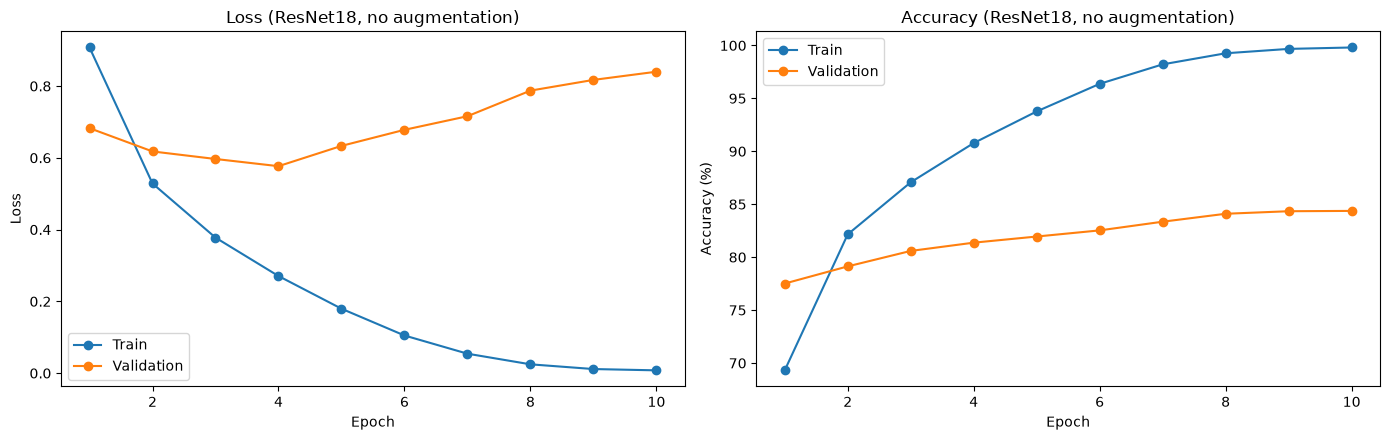

Test Accuracy: 84.37%


In [14]:
## TRAINING WITHOUT AUGMENTATIONS

# Define Parameters
num_epochs = 10
torch.manual_seed(0)
model_noaug = resnet18          # pretrained model from 3.1

# Define Loss func and Optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer, scheduler = make_optimizer_and_scheduler(model_noaug, num_epochs)

# Train Model
hist_noaug = train(model_noaug, loss_fn, optimizer, train_loader, test_loader, num_epochs, device, scheduler)

# Plot Learning Curves
plot_learning_curve(hist_noaug, title='(ResNet18, no augmentation)')

# Evaluate on Test Set
results['no aug'] = test_accuracy(model_noaug, test_loader, device)

Epoch [1/10]  Train Loss: 1.0420  Train Acc: 64.03%  |  Val Loss: 0.7838  Val Acc: 72.69%  |  24.4s
Epoch [2/10]  Train Loss: 0.7140  Train Acc: 75.59%  |  Val Loss: 0.7182  Val Acc: 75.68%  |  20.3s
Epoch [3/10]  Train Loss: 0.6155  Train Acc: 78.98%  |  Val Loss: 0.6100  Val Acc: 79.11%  |  20.3s
Epoch [4/10]  Train Loss: 0.5386  Train Acc: 81.43%  |  Val Loss: 0.5410  Val Acc: 81.93%  |  18.8s
Epoch [5/10]  Train Loss: 0.4862  Train Acc: 83.15%  |  Val Loss: 0.5004  Val Acc: 82.88%  |  18.6s
Epoch [6/10]  Train Loss: 0.4365  Train Acc: 84.89%  |  Val Loss: 0.4992  Val Acc: 83.14%  |  18.5s
Epoch [7/10]  Train Loss: 0.3940  Train Acc: 86.29%  |  Val Loss: 0.4658  Val Acc: 84.49%  |  20.6s
Epoch [8/10]  Train Loss: 0.3493  Train Acc: 87.73%  |  Val Loss: 0.4435  Val Acc: 85.22%  |  53.3s
Epoch [9/10]  Train Loss: 0.3227  Train Acc: 88.57%  |  Val Loss: 0.4334  Val Acc: 85.33%  |  28.2s
Epoch [10/10]  Train Loss: 0.3082  Train Acc: 89.08%  |  Val Loss: 0.4299  Val Acc: 85.87%  |  35.8s

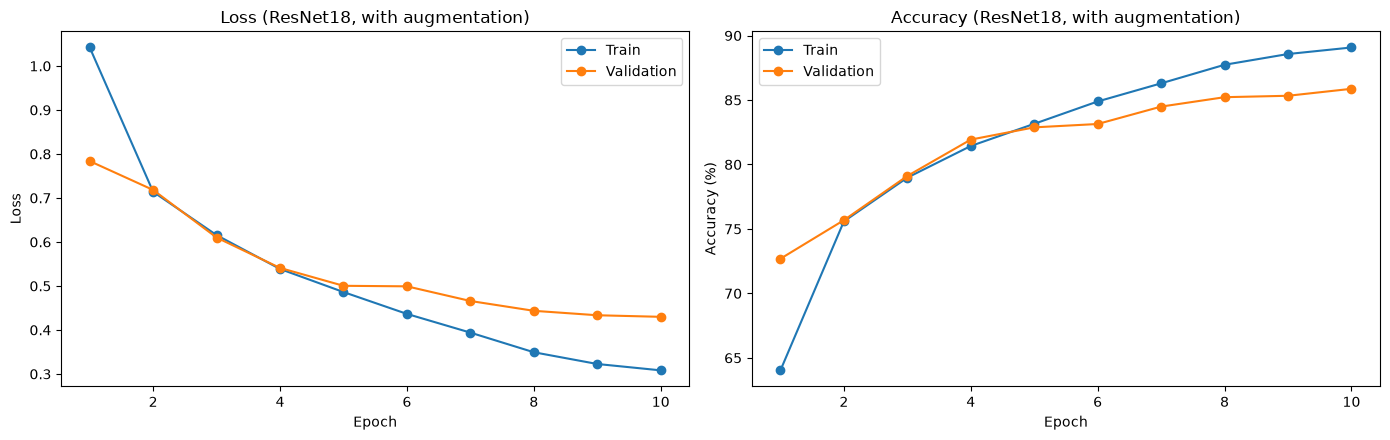

Test Accuracy: 85.87%


In [15]:
## TRAINING WITH AUGMENTATIONS (RandomCrop + HorizontalFlip)

# Define Parameters
num_epochs = 10
torch.manual_seed(0)
model_aug = make_resnet18().to(device)   # fresh pretrained model for a fair comparison

# Define Loss func and Optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer, scheduler = make_optimizer_and_scheduler(model_aug, num_epochs)

# Train Model
hist_aug = train(model_aug, loss_fn, optimizer, train_aug_loader, test_loader, num_epochs, device, scheduler)

# Plot Learning Curves
plot_learning_curve(hist_aug, title='(ResNet18, with augmentation)')

# Evaluate on Test Set
results['aug'] = test_accuracy(model_aug, test_loader, device)

### **3.2.3 Confusion Matrix**

Write code to plot a confusion matrix after training the above ResNet18. Please make sure the axis have class names (defined in Section 1)

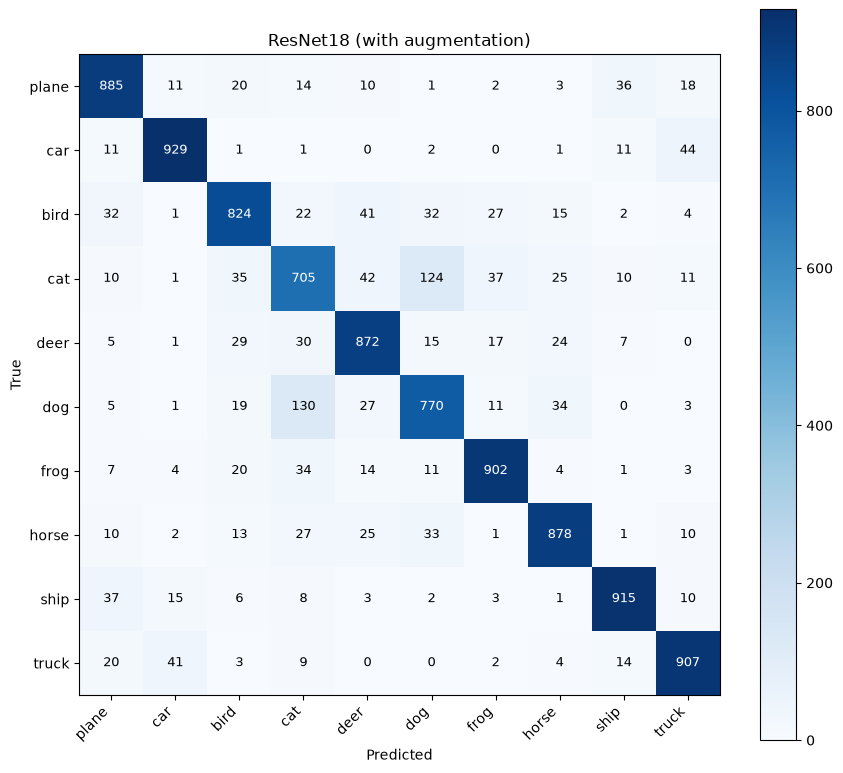

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

def get_predictions(model, loader, device):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for images, labels in loader:
            preds = model(images.to(device)).argmax(1).cpu()
            all_preds.append(preds)
            all_labels.append(labels)
    return torch.cat(all_labels).numpy(), torch.cat(all_preds).numpy()

def plot_confusion_matrix(model, loader, classes, device, title='Confusion Matrix'):
    y_true, y_pred = get_predictions(model, loader, device)
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm, cmap='Blues')
    fig.colorbar(im, ax=ax)
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha='right')
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
    thresh = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha='center', va='center',
                    color='white' if cm[i, j] > thresh else 'black', fontsize=9)
    plt.tight_layout()
    plt.show()
    return cm

cm_aug = plot_confusion_matrix(model_aug, test_loader, classes, device, title='ResNet18 (with augmentation)')

## **3.2.4 Freeze Network**

Initialize a new ResNet18, Freeze all the non-linear or non-fc weights. Hence, we will only be training the fc layers.

Freezing implies setting `requires_grad = False` for selected parameters


In [17]:
# Instantiate Pretrained ResNet18
resnet18_frz = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Freeze all layers (except classifier/linear layers)
for param in resnet18_frz.parameters():
    param.requires_grad = False
# The new fc layer is created after freezing, so its weights are trainable
resnet18_frz.fc = nn.Linear(resnet18_frz.fc.in_features, len(classes))
resnet18_frz = resnet18_frz.to(device)

trainable = sum(p.numel() for p in resnet18_frz.parameters() if p.requires_grad)
total = sum(p.numel() for p in resnet18_frz.parameters())
print(f'Trainable params: {trainable:,} / {total:,}')

# View Model to validate
print(resnet18_frz)

Trainable params: 5,130 / 11,181,642
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affi

### **3.2.5 Train frozen ResNet18**

Retrain the frozen ResNet18 now with the same setup as the previous ResNet18 (same batch size, optimizer, learning rate, etc.) for direct comparison. The results may not be as good that is expected.

Epoch [1/10]  Train Loss: 1.8900  Train Acc: 34.95%  |  Val Loss: 1.9025  Val Acc: 37.49%  |  20.5s
Epoch [2/10]  Train Loss: 1.8389  Train Acc: 37.16%  |  Val Loss: 1.8969  Val Acc: 36.31%  |  16.4s
Epoch [3/10]  Train Loss: 1.8140  Train Acc: 38.05%  |  Val Loss: 1.8495  Val Acc: 38.10%  |  14.4s
Epoch [4/10]  Train Loss: 1.7854  Train Acc: 38.66%  |  Val Loss: 1.8299  Val Acc: 38.51%  |  14.7s
Epoch [5/10]  Train Loss: 1.7612  Train Acc: 39.13%  |  Val Loss: 1.7890  Val Acc: 39.87%  |  14.6s
Epoch [6/10]  Train Loss: 1.7263  Train Acc: 40.12%  |  Val Loss: 1.7782  Val Acc: 39.67%  |  14.8s
Epoch [7/10]  Train Loss: 1.6952  Train Acc: 40.97%  |  Val Loss: 1.7503  Val Acc: 39.60%  |  18.9s
Epoch [8/10]  Train Loss: 1.6671  Train Acc: 41.84%  |  Val Loss: 1.7440  Val Acc: 40.25%  |  14.6s
Epoch [9/10]  Train Loss: 1.6517  Train Acc: 42.45%  |  Val Loss: 1.6965  Val Acc: 42.61%  |  15.1s
Epoch [10/10]  Train Loss: 1.6363  Train Acc: 42.87%  |  Val Loss: 1.6823  Val Acc: 42.48%  |  17.8s

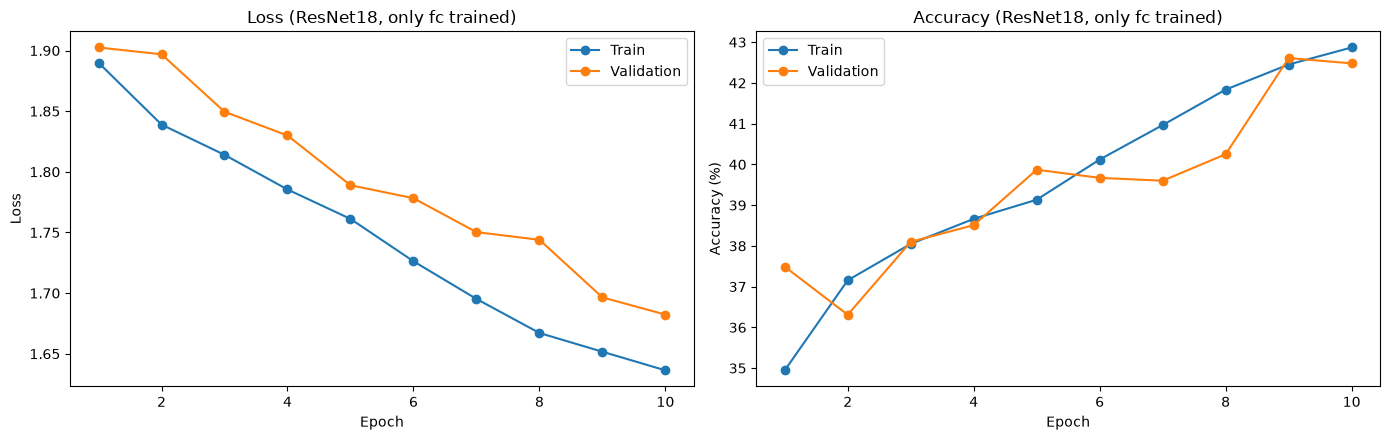

Test Accuracy: 42.61%


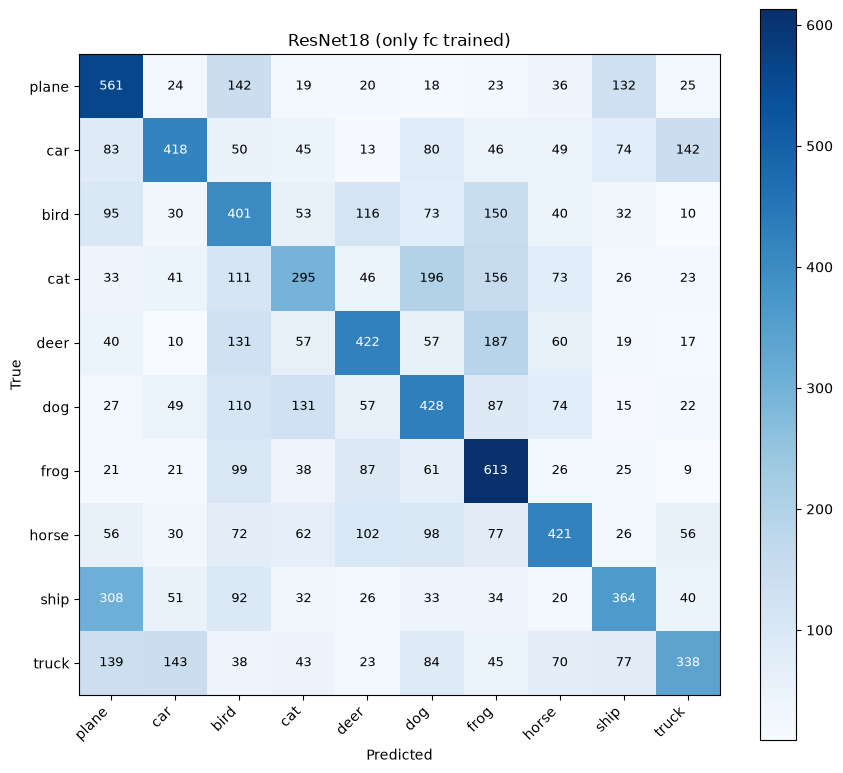

In [18]:
## TRAINING WITH AUGMENTATIONS (same setup as above)

# Define Parameters
num_epochs = 10
torch.manual_seed(0)
loss_fn = nn.CrossEntropyLoss()
optimizer, scheduler = make_optimizer_and_scheduler(resnet18_frz, num_epochs)

# Train the model
hist_frz = train(resnet18_frz, loss_fn, optimizer, train_aug_loader, test_loader, num_epochs, device, scheduler)

# Plot the learning curve
plot_learning_curve(hist_frz, title='(ResNet18, only fc trained)')

# Evaluate on Test Set
results['frozen (fc only)'] = test_accuracy(resnet18_frz, test_loader, device)
cm_frz = plot_confusion_matrix(resnet18_frz, test_loader, classes, device, title='ResNet18 (only fc trained)')

### ❓ **Q 3.2.6 What was the difference when training with and without data augmentations?**

Without augmentation, the model memorized the training set: train accuracy reached **99.81%** but test accuracy was only **84.37%**, and test loss rose from 0.68 to 0.84 during training, a clear sign of **overfitting**. With augmentation (RandomCrop + HorizontalFlip), train accuracy was lower (**89.08%**) because the task is harder, but test accuracy was higher (**85.87%**), test loss was much lower (**0.43**), and the train/test gap shrank from about 15% to 3%. Augmentation therefore generalized better. Each epoch took slightly longer (~26 s vs ~19 s) because of the extra image processing.

___
### ❓ **Q 3.2.7 What is transfer learning and why would it be useful?**

Transfer learning reuses a model trained on a large dataset (here, ResNet18 trained on ImageNet) as the starting point for a new task. Its early layers already detect general features like edges, textures and shapes, so the model only has to adapt those features to the new classes. It is useful because it trains faster, needs much less data, and usually reaches higher accuracy than training from scratch.

___
### ❓ **Q 3.2.8 What was the difference between freezing layers and retraining all? Explain in terms of classification metrics and why you saw such metrics and confusuon matrix. Is what you say as expected?**

Training only the fc layer reached just **42.61%** test accuracy, compared with **85.87%** when retraining the whole network, with only 5,130 of 11.2M parameters trainable. Its confusion matrix is much more spread out: every class is confused with many others, the worst being cat (only 295/1000 correct), and there are large confusions such as ship → plane (308) and car ↔ truck (~140 each). The fully trained model's main mistakes were between genuinely similar classes, cat ↔ dog (~125 each way) and car → truck (44).

This is expected. The frozen features were learned on 224×224 ImageNet photos, so they do not fit tiny 32×32 CIFAR images well, and a single linear layer cannot fix features it cannot change. It can only separate classes using broad cues like color and background, which is why ships and planes (both on blue backgrounds) get mixed up. Retraining every layer lets the features themselves adapt to the new data.

___
### ❓ **Q 3.2.9 For a pretrained model like ResNet, in what general scenarios would you (1) freeze your pretrained weights adn retrain last layer, (2) retrain entire architecture, and (3) Freeze all convolution layer weights and retrain all FC layers? Explain with example scenarios if possible.**

1. **Freeze the pretrained weights and retrain only the last layer:** when the dataset is small and similar to the pretraining data. Example: classifying a few dog breeds using ImageNet features. There is too little data to safely change the features, and they already fit the task.
2. **Retrain the entire network:** when the dataset is large, or very different from the pretraining data. Example: medical X-rays, satellite images, or (as here) very low-resolution CIFAR images. The features themselves need to change.
3. **Freeze all conv layers and retrain all FC layers:** when the dataset is medium-sized and fairly similar to the original. The conv features still apply, but the classifier needs more capacity than one linear layer. Example: classifying product photos for an online store.

___


### **3.2.10 Train frozen ResNet18 for better performance**

You may have noticed only training just the fc layer did not yield good performance. Now, you must try to investigate trying to freeze as much of the original model as possible for best results.


*   Keep fc layer unfrozen, and unfreeze the last block (in layer4 of resnet18)
*   You pick which layers to unfreeze!

Investigate the maximize the layers to unfreeze to yield best balance between performance to training time.

Trainable: 8398858 / 11181642
Epoch [1/10]  Train Loss: 1.3682  Train Acc: 52.11%  |  Val Loss: 1.2094  Val Acc: 58.90%  |  17.2s
Epoch [2/10]  Train Loss: 1.1031  Train Acc: 61.27%  |  Val Loss: 1.0899  Val Acc: 63.99%  |  16.0s
Epoch [3/10]  Train Loss: 1.0142  Train Acc: 64.31%  |  Val Loss: 1.2556  Val Acc: 63.03%  |  16.6s
Epoch [4/10]  Train Loss: 0.9669  Train Acc: 66.02%  |  Val Loss: 1.1279  Val Acc: 65.02%  |  16.2s
Epoch [5/10]  Train Loss: 0.9199  Train Acc: 67.30%  |  Val Loss: 0.9405  Val Acc: 67.57%  |  15.8s
Epoch [6/10]  Train Loss: 0.8813  Train Acc: 68.95%  |  Val Loss: 0.9338  Val Acc: 67.83%  |  16.2s
Epoch [7/10]  Train Loss: 0.8440  Train Acc: 69.96%  |  Val Loss: 0.9326  Val Acc: 67.97%  |  17.5s
Epoch [8/10]  Train Loss: 0.8208  Train Acc: 71.03%  |  Val Loss: 0.8952  Val Acc: 69.41%  |  169.0s
Epoch [9/10]  Train Loss: 0.8006  Train Acc: 71.71%  |  Val Loss: 0.8676  Val Acc: 70.05%  |  15.2s
Epoch [10/10]  Train Loss: 0.7807  Train Acc: 72.30%  |  Val Loss: 0.

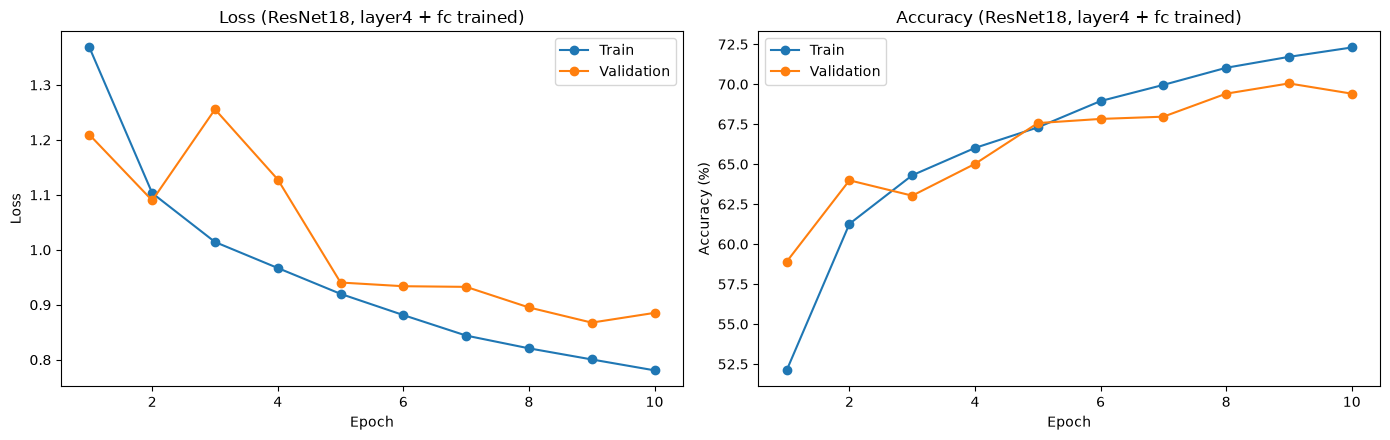

Test Accuracy: 70.05%


In [19]:
# Instantiate Pretrained ResNet18
resnet18_frz = make_resnet18()

# Unfreeze the last block (in layer4 of resnet18) + fc; freeze everything else
for name, param in resnet18_frz.named_parameters():
    param.requires_grad = name.startswith('layer4') or name.startswith('fc')
resnet18_frz = resnet18_frz.to(device)
print('Trainable:', sum(p.numel() for p in resnet18_frz.parameters() if p.requires_grad),
      '/', sum(p.numel() for p in resnet18_frz.parameters()))

## TRAINING WITH AUGMENTATIONS
# Define Parameters
num_epochs = 10
torch.manual_seed(0)
loss_fn = nn.CrossEntropyLoss()
optimizer, scheduler = make_optimizer_and_scheduler(resnet18_frz, num_epochs)

# Train the model
t0 = time.time()
hist_l4 = train(resnet18_frz, loss_fn, optimizer, train_aug_loader, test_loader, num_epochs, device, scheduler)
print(f'Total training time: {time.time() - t0:.1f}s')

# Plot the learning curve
plot_learning_curve(hist_l4, title='(ResNet18, layer4 + fc trained)')

# Evaluate on Test Set
results['layer4 + fc'] = test_accuracy(resnet18_frz, test_loader, device)

Trainable: 10498570 / 11181642
Epoch [1/10]  Train Loss: 1.1367  Train Acc: 60.10%  |  Val Loss: 0.8510  Val Acc: 70.75%  |  18.3s
Epoch [2/10]  Train Loss: 0.8361  Train Acc: 70.86%  |  Val Loss: 0.7340  Val Acc: 74.67%  |  17.6s
Epoch [3/10]  Train Loss: 0.7480  Train Acc: 73.78%  |  Val Loss: 0.6943  Val Acc: 76.00%  |  17.3s
Epoch [4/10]  Train Loss: 0.6930  Train Acc: 75.76%  |  Val Loss: 0.6649  Val Acc: 77.09%  |  19.3s
Epoch [5/10]  Train Loss: 0.6319  Train Acc: 77.69%  |  Val Loss: 0.6374  Val Acc: 78.31%  |  20.0s
Epoch [6/10]  Train Loss: 0.5904  Train Acc: 79.12%  |  Val Loss: 0.6149  Val Acc: 78.72%  |  217.3s
Epoch [7/10]  Train Loss: 0.5487  Train Acc: 80.54%  |  Val Loss: 0.6031  Val Acc: 79.36%  |  18.1s
Epoch [8/10]  Train Loss: 0.5214  Train Acc: 81.68%  |  Val Loss: 0.5869  Val Acc: 79.79%  |  17.7s
Epoch [9/10]  Train Loss: 0.4916  Train Acc: 82.73%  |  Val Loss: 0.5848  Val Acc: 79.97%  |  17.5s
Epoch [10/10]  Train Loss: 0.4767  Train Acc: 83.08%  |  Val Loss: 0

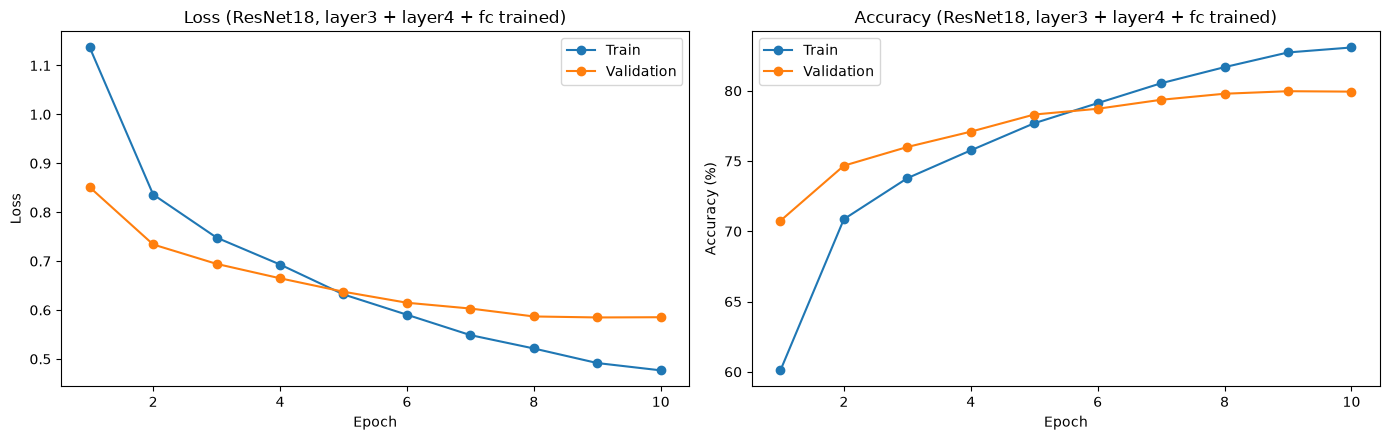

Test Accuracy: 79.97%
                no aug: 84.37%
                   aug: 85.87%
      frozen (fc only): 42.61%
           layer4 + fc: 70.05%
  layer3 + layer4 + fc: 79.97%


In [20]:
# Instantiate Pretrained ResNet18
resnet18_frz = make_resnet18()

# Freeze whichever layers you choose for best performance:
# freeze the stem + layer1 + layer2 (generic edge/texture features),
# train layer3 + layer4 + fc (more task-specific features).
TRAIN_PREFIXES = ('layer3', 'layer4', 'fc')
for name, param in resnet18_frz.named_parameters():
    param.requires_grad = name.startswith(TRAIN_PREFIXES)
resnet18_frz = resnet18_frz.to(device)
print('Trainable:', sum(p.numel() for p in resnet18_frz.parameters() if p.requires_grad),
      '/', sum(p.numel() for p in resnet18_frz.parameters()))

## TRAINING WITH AUGMENTATIONS
# Define Parameters
num_epochs = 10
torch.manual_seed(0)
loss_fn = nn.CrossEntropyLoss()
optimizer, scheduler = make_optimizer_and_scheduler(resnet18_frz, num_epochs)

# Train the model
t0 = time.time()
hist_l34 = train(resnet18_frz, loss_fn, optimizer, train_aug_loader, test_loader, num_epochs, device, scheduler)
print(f'Total training time: {time.time() - t0:.1f}s')

# Plot the learning curve
plot_learning_curve(hist_l34, title='(ResNet18, layer3 + layer4 + fc trained)')

# Evaluate on Test Set
results['layer3 + layer4 + fc'] = test_accuracy(resnet18_frz, test_loader, device)

# Summary of all runs
for k, v in results.items():
    print(f'{k:>22}: {v:.2f}%')


### ❓ **Q 3.2.11 Which layers did you freeze to yield the best performance vs training time balance? Can you give any intuition as to why this worked well? Compare it with unfreezing only the fc layer and explain why it performs better.**

| Trainable layers | Test accuracy | Training time (10 epochs) |
|---|---|---|
| fc only | 42.61% | ~162 s |
| layer4 + fc | 70.05% | ~315 s |
| layer3 + layer4 + fc | 79.97% | ~381 s |
| All layers (Section 3.2.2, with augmentation) | 85.87% | ~259 s |

Among the partially frozen models, freezing the stem, layer1 and layer2 and training **layer3 + layer4 + fc** gave the best balance (**79.97%**). Accuracy rose steadily as more layers were unfrozen. Early layers learn generic edges and textures that transfer well, so they can stay frozen. Later layers learn larger, more ImageNet-specific shapes, so they need to adapt to CIFAR. Training only fc does far worse because it can only re-weight fixed features and cannot change what the network detects.

Two notes on these results. The measured times do not follow the expected pattern (freezing layers should make training faster, since gradients are not computed for frozen layers), so they were likely affected by other programs using the laptop during those runs. Also, full fine-tuning was best overall here. CIFAR's 32×32 images are very different from ImageNet's, and by layer4 the feature map is only 1×1, so even the early features benefit from adapting. With larger or more ImageNet-like images, freezing early layers would cost less accuracy.

___
___
# End of Phase 2 😊🥳